# Adaline

In [49]:
import numpy as np

In [50]:
# Define the Adaline class
class Adaline(object):
    def __init__(self, no_of_inputs, epochs=100, learning_rate=0.01):
        self.epochs = epochs
        self.learning_rate = learning_rate
        self.weights = np.zeros(no_of_inputs + 1)  # Including bias term
        self.cost = []  # To track the cost over epochs

    def activation(self, x):
        """The activation function is a linear one for Adaline."""
        return x

    def predict(self, inputs):
        """Predict the output by calculating the weighted sum (including bias)."""
        return self.activation(np.dot(inputs, self.weights[1:]) + self.weights[0])

    # SSE-style update (batch gradient descent)
    def train(self, training_inputs, labels):
        """Train the model using gradient descent."""
        for _ in range(self.epochs):
            output = np.array([self.predict(inputs) for inputs in training_inputs])
            errors = labels - output
            self.weights[1:] += self.learning_rate * np.dot(training_inputs.T, errors)
            self.weights[0] += self.learning_rate * errors.sum()

            # Calculate cost (Sum of Squared Errors)
            cost = (errors**2).sum() / 2.0
            self.cost.append(cost)

    # MSE-style update (batch gradient descent)
    def train_mse(self, training_inputs, labels):
        """Train the model using gradient descent."""
        n = len(training_inputs)  # number of samples
        for _ in range(self.epochs):
            output = np.array([self.predict(inputs) for inputs in training_inputs])
            errors = labels - output

            self.weights[1:] += self.learning_rate * np.dot(training_inputs.T, errors) / n
            self.weights[0]  += self.learning_rate * errors.sum() / n

            cost = (errors**2).sum() / (2.0 * n)   # MSE version
            self.cost.append(cost)



In [51]:
# Example training data for AND logic
training_inputs = np.array([[1, 1], [1, 0], [0, 1], [0, 0]])
labels = np.array([1, 0, 0, 0])

# training_inputs = np.array([[1, 1], [0, 1], [0, 0]])
# labels = np.array([1, 0, 0])

In [52]:
# SSE
# Instantiate and train the Adaline model
adaline = Adaline(2, 300, 0.01)
adaline.train(training_inputs, labels)
# adaline.train_mse(training_inputs, labels)

In [53]:
# # MSE
# adaline = Adaline(2)
# adaline.train_mse(training_inputs, labels)

In [54]:
# Predictions after training
print('Prediction for [1,1]:', adaline.predict(np.array([1, 1])))  # Expecting a value close to 1
print('Prediction for [0,1]:', adaline.predict(np.array([0, 1])))  # Expecting a value close to 0
print('Prediction for [1,0]:', adaline.predict(np.array([1, 0])))  # Expecting a value close to 0
print('Prediction for [0,0]:', adaline.predict(np.array([0, 0])))  # Expecting a value close to 0

Prediction for [1,1]: 0.7031673699114152
Prediction for [0,1]: 0.2607112561528645
Prediction for [1,0]: 0.2607112561528645
Prediction for [0,0]: -0.18174485760568607


In [55]:
# Quantization

raw_output = adaline.predict(np.array([1, 0]))

if raw_output >= 0.5:
    predicted_class = 1
else:
    predicted_class = 0

print(predicted_class)

0


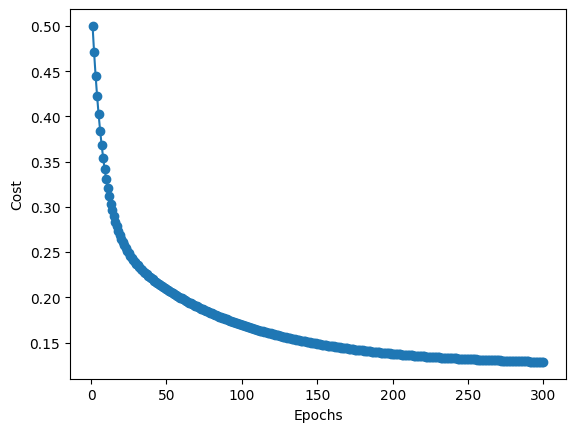

In [56]:
import matplotlib.pyplot as plt

plt.plot(range(1, len(adaline.cost) + 1), adaline.cost, marker='o')
plt.xlabel('Epochs')
plt.ylabel('Cost')
plt.show()